# Análise de Agrupamento com K-means — Dow Jones

**Trabalho:** TDE 4 — Matemática aplicada à computação

**Algoritmo:** K-means com inicialização K-means++

**Base de dados:** Dow Jones Index — UCI Machine Learning Repository

**Integrantes:** Rafael Bernardo e Paulo Tavares

---

## 1. Base de dados e preparação

O conjunto Dow Jones Index contém observações semanais de ações de empresas que compõem o índice Dow Jones.

Foram selecionados quatro atributos numéricos: volume de negociação, variação percentual do preço, dias até o próximo dividendo e retorno percentual dos dividendos.

Nesta etapa, os dados são carregados, inspecionados e preparados para a aplicação do algoritmo.

O objetivo é identificar agrupamentos em observações do mercado financeiro por meio de atributos relacionados ao volume de negociação, variação de preços e dividendos.

In [27]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [28]:
dataset = fetch_ucirepo(id=312)

df = dataset.data.original.copy()

print("Dimensões:", df.shape)
print("\nColunas:")
print(df.columns.tolist())

display(df.head())

print("\nValores ausentes:")
print(df.isnull().sum().sum())

Dimensões: (750, 16)

Colunas:
['quarter', 'stock', 'date', 'open', 'high', 'low', 'close', 'volume', 'percent_change_price', 'percent_change_volume_over_last_wk', 'previous_weeks_volume', 'next_weeks_open', 'next_weeks_close', 'percent_change_next_weeks_price', 'days_to_next_dividend', 'percent_return_next_dividend']


,quarter,stock,date,open,high,low,close,volume,percent_change_price,percent_change_volume_over_last_wk,previous_weeks_volume,next_weeks_open,next_weeks_close,percent_change_next_weeks_price,days_to_next_dividend,percent_return_next_dividend
0,1,AA,1/7/2011,$15.82,$16.72,$15.78,$16.42,239655616,3.79267,NaN,NaN,$16.71,$15.97,-4.428490,26,0.182704
1,1,AA,1/14/2011,$16.71,$16.71,$15.64,$15.97,242963398,-4.42849,1.380223,239655616.0,$16.19,$15.79,-2.470660,19,0.187852
2,1,AA,1/21/2011,$16.19,$16.38,$15.60,$15.79,138428495,-2.47066,-43.024959,242963398.0,$15.87,$16.13,1.638310,12,0.189994
3,1,AA,1/28/2011,$15.87,$16.63,$15.82,$16.13,151379173,1.63831,9.355500,138428495.0,$16.18,$17.14,5.933250,5,0.185989
4,1,AA,2/4/2011,$16.18,$17.39,$16.18,$17.14,154387761,5.93325,1.987452,151379173.0,$17.33,$17.37,0.230814,97,0.175029



Valores ausentes:
60


In [29]:
# Seleção dos quatro atributos numéricos
atributos = [
    "volume",
    "percent_change_price",
    "days_to_next_dividend",
    "percent_return_next_dividend"
]

X_original = df[atributos].copy()

# Garantir que todos os atributos sejam numéricos
X_original = X_original.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Valores ausentes:")
print(X_original.isnull().sum())

print("\nDimensões antes do tratamento:", X_original.shape)

# Remover registros incompletos, se existirem
X_original = X_original.dropna()

print("\nDimensões finais:", X_original.shape)

display(X_original.head())

Valores ausentes:
volume                          0
percent_change_price            0
days_to_next_dividend           0
percent_return_next_dividend    0
dtype: int64

Dimensões antes do tratamento: (750, 4)

Dimensões finais: (750, 4)


,volume,percent_change_price,days_to_next_dividend,percent_return_next_dividend
0,239655616,3.79267,26,0.182704
1,242963398,-4.42849,19,0.187852
2,138428495,-2.47066,12,0.189994
3,151379173,1.63831,5,0.185989
4,154387761,5.93325,97,0.175029


## 2. Padronização dos dados

Foi utilizado o StandardScaler para padronizar os atributos, colocando-os em escalas comparáveis.

Essa transformação é necessária porque o K-means utiliza distâncias para formar os agrupamentos e pode ser influenciado por diferenças nas escalas das variáveis.

A base utilizada possui 750 observações semanais e 16 atributos, referentes a 30 empresas do índice Dow Jones.

In [30]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_original)

X_padronizado = pd.DataFrame(
    X_scaled,
    columns=atributos,
    index=X_original.index
)

print("ANTES DA PADRONIZAÇÃO:")
display(X_original.head())

print("DEPOIS DA PADRONIZAÇÃO:")
display(X_padronizado.head())

ANTES DA PADRONIZAÇÃO:


,volume,percent_change_price,days_to_next_dividend,percent_return_next_dividend
0,239655616,3.79267,26,0.182704
1,242963398,-4.42849,19,0.187852
2,138428495,-2.47066,12,0.189994
3,151379173,1.63831,5,0.185989
4,154387761,5.93325,97,0.175029


DEPOIS DA PADRONIZAÇÃO:


,volume,percent_change_price,days_to_next_dividend,percent_return_next_dividend
0,0.771212,1.487366,-0.572849,-1.667730
1,0.792103,-1.780016,-0.724024,-1.650867
2,0.131879,-1.001905,-0.875198,-1.643850
3,0.213673,0.631147,-1.026372,-1.656970
4,0.232675,2.338109,0.960489,-1.692871


## 3. Aplicação e avaliação do K-means

Foi aplicado o K-means com inicialização K-means++, considerando valores de k entre 1 e 10 e 10 inicializações por configuração.

A avaliação utiliza o método do cotovelo, baseado na inércia, e o coeficiente de silhueta, que permite analisar a coesão e a separação dos agrupamentos.

,k,J(k)
0,1,3000.000000
1,2,2416.534149
2,3,1922.455082
3,4,1540.505522
4,5,1244.704395
5,6,1117.397409
6,7,998.796344
7,8,924.549970
8,9,873.713838
9,10,820.672339


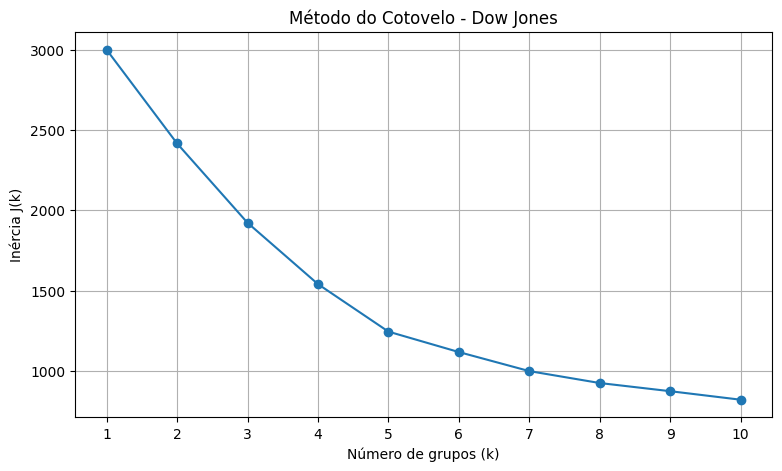

In [31]:
resultados = []

for k in range(1, 11):

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    modelo.fit(X_scaled)

    resultados.append({
        "k": k,
        "J(k)": modelo.inertia_
    })

resultados_df = pd.DataFrame(resultados)

display(resultados_df)

plt.figure(figsize=(9, 5))

plt.plot(
    resultados_df["k"],
    resultados_df["J(k)"],
    marker="o"
)

plt.title("Método do Cotovelo - Dow Jones")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inércia J(k)")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

,k,Silhueta média
0,2,0.444710
1,3,0.465097
2,4,0.230312
3,5,0.254269
4,6,0.225829
5,7,0.253524
6,8,0.232212
7,9,0.236513
8,10,0.233688


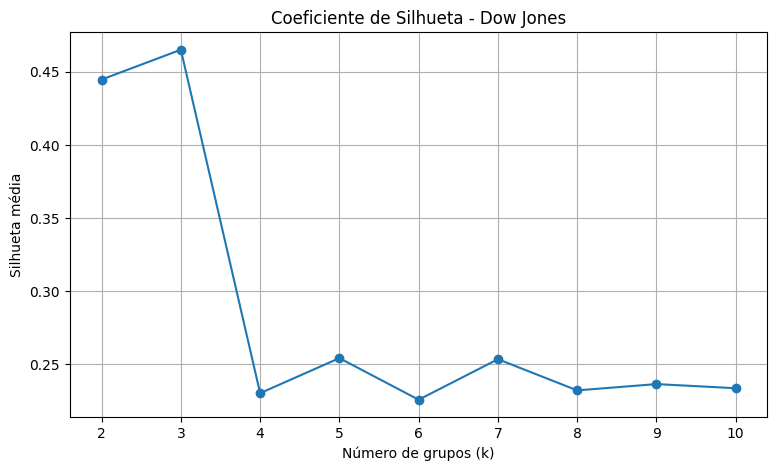

In [32]:
silhuetas = []

for k in range(2, 11):

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = modelo.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhuetas.append({
        "k": k,
        "Silhueta média": score
    })

silhueta_df = pd.DataFrame(silhuetas)

display(silhueta_df)

plt.figure(figsize=(9, 5))

plt.plot(
    silhueta_df["k"],
    silhueta_df["Silhueta média"],
    marker="o"
)

plt.title("Coeficiente de Silhueta - Dow Jones")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Silhueta média")
plt.xticks(range(2, 11))
plt.grid()
plt.show()

In [33]:
comparacao = resultados_df.merge(
    silhueta_df,
    on="k",
    how="left"
)

display(comparacao)

melhor_silhueta = silhueta_df.loc[
    silhueta_df["Silhueta média"].idxmax()
]

print("Melhor k pela silhueta:", int(melhor_silhueta["k"]))
print("Silhueta média:", round(melhor_silhueta["Silhueta média"], 4))

,k,J(k),Silhueta média
0,1,3000.000000,NaN
1,2,2416.534149,0.444710
2,3,1922.455082,0.465097
3,4,1540.505522,0.230312
4,5,1244.704395,0.254269
5,6,1117.397409,0.225829
6,7,998.796344,0.253524
7,8,924.549970,0.232212
8,9,873.713838,0.236513
9,10,820.672339,0.233688


Melhor k pela silhueta: 3
Silhueta média: 0.4651


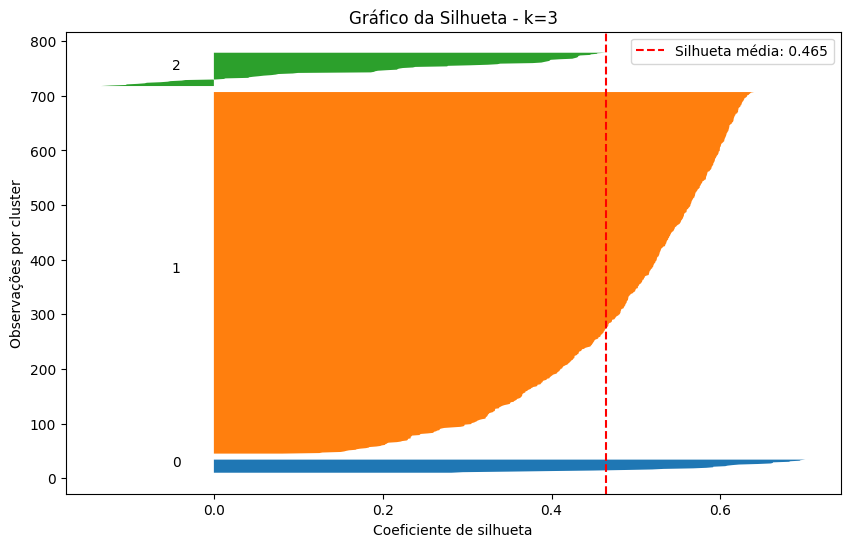

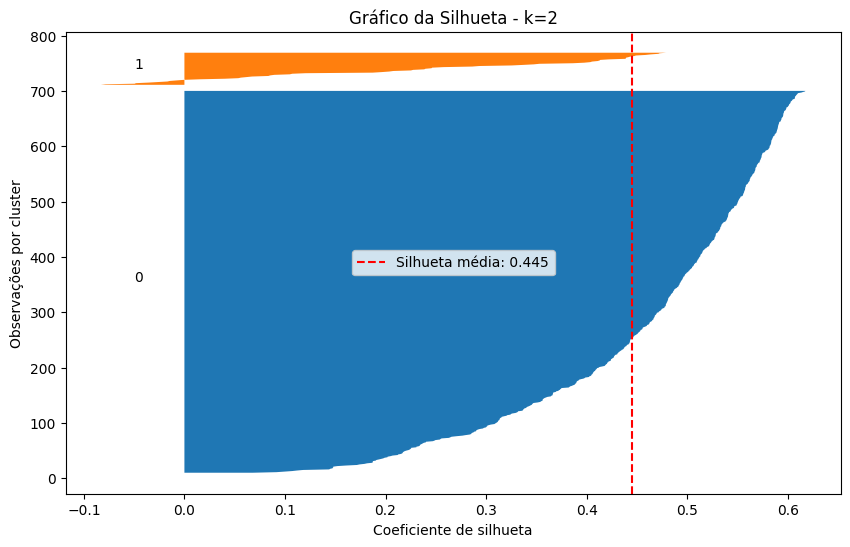

In [34]:
def grafico_silhueta(k):

    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = modelo.fit_predict(X_scaled)

    valores = silhouette_samples(X_scaled, labels)

    media = silhouette_score(X_scaled, labels)

    plt.figure(figsize=(10, 6))

    inicio = 10

    for i in range(k):

        valores_cluster = valores[labels == i]
        valores_cluster.sort()

        tamanho = len(valores_cluster)
        fim = inicio + tamanho

        plt.fill_betweenx(
            np.arange(inicio, fim),
            0,
            valores_cluster
        )

        plt.text(-0.05, inicio + tamanho / 2, str(i))

        inicio = fim + 10

    plt.axvline(
        media,
        color="red",
        linestyle="--",
        label=f"Silhueta média: {media:.3f}"
    )

    plt.title(f"Gráfico da Silhueta - k={k}")
    plt.xlabel("Coeficiente de silhueta")
    plt.ylabel("Observações por cluster")
    plt.legend()
    plt.show()


grafico_silhueta(3)
grafico_silhueta(2)

## 4. Modelo final e visualização

Com base nas métricas obtidas, será definido o número de clusters do modelo final.

Serão analisados os tamanhos dos grupos e seus centroides, convertidos para as unidades originais. Também será utilizada a técnica PCA para representar os agrupamentos em duas dimensões.

In [35]:
modelo_final = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels_finais = modelo_final.fit_predict(X_scaled)

# Adicionar os grupos ao dataset
resultado = X_original.copy()
resultado["Cluster"] = labels_finais

# Quantidade de registros em cada grupo
print("TAMANHO DOS CLUSTERS:")
display(
    resultado["Cluster"].value_counts().sort_index()
)

# Converter centroides para a escala original
centroides = scaler.inverse_transform(
    modelo_final.cluster_centers_
)

centroides_df = pd.DataFrame(
    centroides,
    columns=atributos
)

centroides_df.index.name = "Cluster"

print("\nCENTROIDES NA ESCALA ORIGINAL:")
display(centroides_df.round(3))

print("\nINÉRCIA FINAL:")
print(modelo_final.inertia_)

TAMANHO DOS CLUSTERS:


,count
Cluster,
0,25
1,663
2,62



CENTROIDES NA ESCALA ORIGINAL:


,volume,percent_change_price,days_to_next_dividend,percent_return_next_dividend
Cluster,,,,
0,4.744367e+07,0.175,252.040,0.972
1,8.272726e+07,0.205,46.018,0.719
2,5.181707e+08,-1.651,41.661,0.293



INÉRCIA FINAL:
1922.45508176018


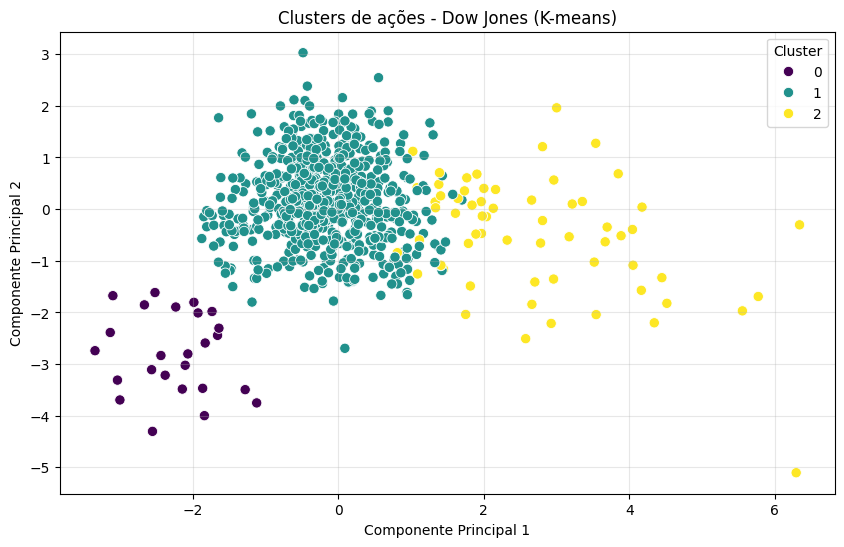

Variância explicada pelas duas componentes: 59.41 %


In [36]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=labels_finais,
    palette="viridis",
    s=55
)

plt.title("Clusters de ações - Dow Jones (K-means)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

print(
    "Variância explicada pelas duas componentes:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

## 5. Interpretação e considerações finais

Nesta etapa, são analisadas as características dos clusters, suas distribuições e as limitações dos resultados.

A interpretação considera o desbalanceamento dos grupos e o fato de que a base contém observações semanais de empresas, não empresas independentes.

In [37]:
# Distribuição percentual dos clusters
print("DISTRIBUIÇÃO DOS CLUSTERS (%)")

display(
    resultado["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# Comparação posterior com as ações originais
comparacao_acoes = df.loc[
    X_original.index,
    ["stock"]
].copy()

comparacao_acoes["Cluster"] = labels_finais

print("\nQUANTIDADE DE AÇÕES POR CLUSTER")

display(
    pd.crosstab(
        comparacao_acoes["Cluster"],
        comparacao_acoes["stock"]
    )
)

# Estatísticas descritivas por grupo
print("\nESTATÍSTICAS POR CLUSTER")

display(
    resultado.groupby("Cluster")[atributos].agg(
        ["mean", "median", "std"]
    ).round(3)
)

DISTRIBUIÇÃO DOS CLUSTERS (%)


,proportion
Cluster,
0,3.33
1,88.40
2,8.27



QUANTIDADE DE AÇÕES POR CLUSTER


stock,AA,AXP,BA,BAC,CAT,CSCO,CVX,DD,DIS,GE,...,MRK,MSFT,PFE,PG,T,TRV,UTX,VZ,WMT,XOM
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,25,0,...,0,0,0,0,0,0,0,0,0,0
1,22,25,25,0,25,5,25,25,0,22,...,25,18,25,25,25,25,25,25,25,25
2,3,0,0,25,0,20,0,0,0,3,...,0,7,0,0,0,0,0,0,0,0



ESTATÍSTICAS POR CLUSTER


volume                            percent_change_price         \
                 mean       median           std                 mean median   
Cluster                                                                        
0        4.744367e+07   42131642.0  1.532448e+07                0.175  0.280   
1        8.272726e+07   48599369.0  8.048721e+07                0.205  0.079   
2        5.181707e+08  457871181.0  2.439436e+08               -1.651 -1.217   

               days_to_next_dividend                 \
           std                  mean median     std   
Cluster                                               
0        2.866               252.040  252.0  51.502   
1        2.301                46.018   47.0  26.532   
2        3.733                41.661   33.0  28.007   

        percent_return_next_dividend                
                                mean median    std  
Cluster                                             
0                              0.972  0.963  0.045  
1                              0.719  0.689  0.286  
2                              0.293  0.302  0.231